# Entrenamiento de CNN ResNet-18 con Transfer Learning
## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Entrenar inicialmente solo la capa clasificadora y descongelar `layer4` en `UNFREEZE_EPOCH` con una tasa de aprendizaje menor.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Evaluar el modelo de la última época sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos finales del modelo entrenado.

In [1]:
# Importaciones
import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen_desde_metadata,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CUDA - NVIDIA GeForce GTX 1650


In [4]:
# Parámetros

# Clases
CLASES_A_PROCESAR = [*range(1, 12)]

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3
UNFREEZE_EPOCH = 4  # Índice desde cero: se descongela al iniciar la época 11.
BACKBONE_LR_FACTOR = 0.1
BACKBONE_LR = LR * BACKBONE_LR_FACTOR

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Datos de entrada y división persistida
DATA_DIR = PATHS.DATA_DIVIDIDO

In [5]:
# Parameters
DATASET_NAME = "cuadrados"
MODEL_NAME = "resnet18"
BATCH_SIZE = 16
EPOCHS = 30
LR = 0.001
ENABLE_UNFREEZE = False
UNFREEZE_EPOCH = 10
BACKBONE_LR_FACTOR = 0.1
USE_CLASS_WEIGHTS = False
ENABLE_HORIZONTAL_FLIP = True
FLIP_PROBABILITY = 0.5
ENABLE_ROTATION = True
ROTATION_DEGREES = 15
ENABLE_SCALING = True
SCALING_FACTOR_INTERVAL = (0.8, 1.0)
IMG_SIZE = 224
PIXEL_FILL = [255, 255, 255]
SEED = 42
TEST_VAL_FRACTION = 0.3
TEST_FRACTION_OF_TEMP = 0.5
NUM_WORKERS = 8
USE_AMP = True
USE_CHANNELS_LAST = True
ENABLE_MODEL_COMPILE = False
RUN_NAME = "bs16_lr1e-3_flip05_base"


## División de datos

La pertenencia de cada imagen a `train`, `val` o `test` se lee de la metadata generada por el notebook de división. La relación se realiza mediante `ruta_relativa`; por tanto, el split no se recalcula aunque cambien la semilla o los parámetros del entrenamiento.

In [6]:
# Metadata, transformaciones y dataloaders
metadata_split = cargar_metadata(DATA_DIR)

config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)

dataloaders = crear_dataloaders_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    configuracion_transformaciones=config_transformaciones,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print(f"Metadata de split: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print("Clases:", *class_names)
print(
    f"Split persistido -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Metadata de split: data/10.cuadrados_divididos_en_train_val_y_test/metadata.csv
Clases: clase01 clase02 clase03 clase04 clase05 clase06 clase07 clase08 clase09 clase10 clase11
Split persistido -> train: 756, val: 162, test: 163


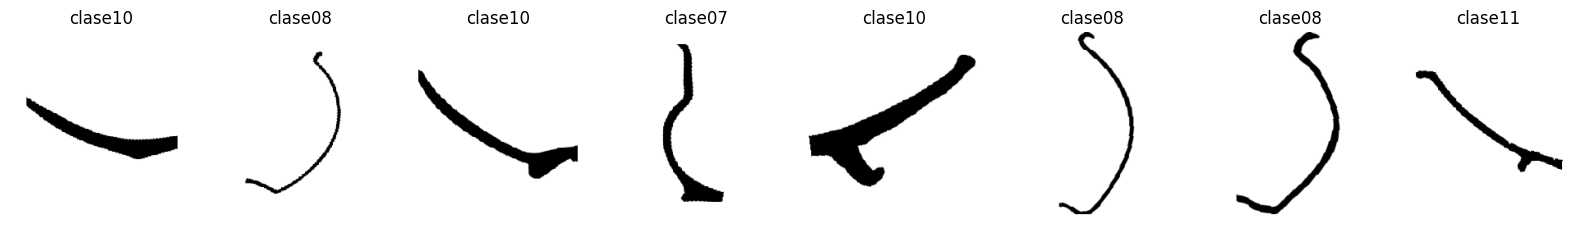

In [7]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(loader=train_loader, nombres_clases=class_names, cantidad=8)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [8]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada()
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [9]:
# Entrenamiento y validación
historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    epochs=EPOCHS,
    model_name=MODEL_NAME,
    unfreeze_epoch=UNFREEZE_EPOCH,
    backbone_lr=BACKBONE_LR,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/30
Train Loss: 1.8570 | Train Acc: 0.4749 | Val Loss: 1.6898 | Val Acc: 0.5000
Tiempo de epoch: 0:00:08.272398 



Epoch 2/30
Train Loss: 1.4024 | Train Acc: 0.5688 | Val Loss: 1.4113 | Val Acc: 0.5988
Tiempo de epoch: 0:00:05.862210 



Epoch 3/30
Train Loss: 1.1425 | Train Acc: 0.6362 | Val Loss: 1.2700 | Val Acc: 0.6173
Tiempo de epoch: 0:00:05.847230 



Epoch 4/30
Train Loss: 1.0347 | Train Acc: 0.6825 | Val Loss: 1.2367 | Val Acc: 0.6235
Tiempo de epoch: 0:00:05.855334 



Epoch 5/30
Train Loss: 1.0170 | Train Acc: 0.6733 | Val Loss: 1.0954 | Val Acc: 0.6358
Tiempo de epoch: 0:00:05.291354 



Epoch 6/30
Train Loss: 0.9113 | Train Acc: 0.7275 | Val Loss: 0.9916 | Val Acc: 0.7099
Tiempo de epoch: 0:00:05.748508 



... (20 outputs left out)

Epoch 27/30
Train Loss: 0.1997 | Train Acc: 0.9339 | Val Loss: 0.3885 | Val Acc: 0.8580
Tiempo de epoch: 0:00:07.570317 



Epoch 28/30
Train Loss: 0.2038 | Train Acc: 0.9431 | Val Loss: 0.4124 | Val Acc: 0.8704
Tiempo de epoch: 0:00:07.516228 



Epoch 29/30
Train Loss: 0.1785 | Train Acc: 0.9550 | Val Loss: 0.3353 | Val Acc: 0.8827
Tiempo de epoch: 0:00:07.543307 



Epoch 30/30
Train Loss: 0.2394 | Train Acc: 0.9392 | Val Loss: 0.3634 | Val Acc: 0.8765
Tiempo de epoch: 0:00:07.589333 



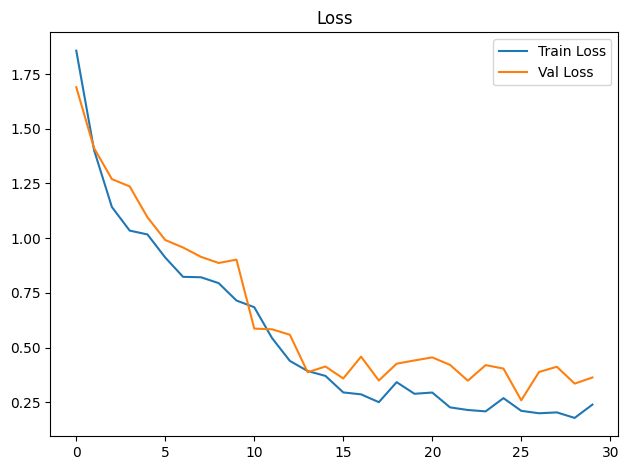

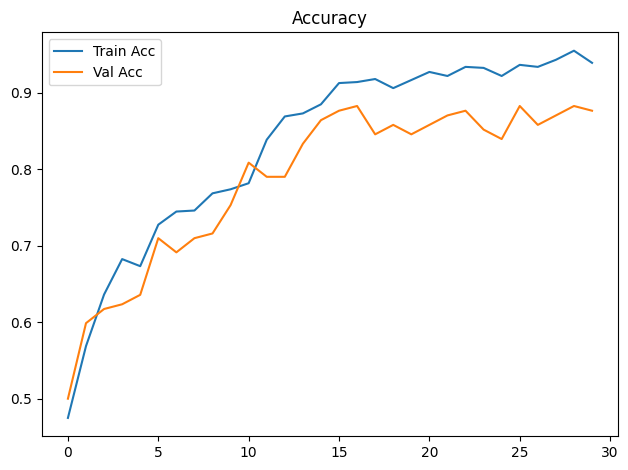

In [10]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.8957
              precision    recall  f1-score   support

     clase01       1.00      1.00      1.00         4
     clase02       1.00      0.29      0.44         7
     clase03       0.75      0.82      0.78        11
     clase04       0.00      0.00      0.00         1
     clase05       0.90      1.00      0.95         9
     clase06       1.00      0.57      0.73         7
     clase07       0.78      1.00      0.88         7
     clase08       0.89      0.95      0.92        42
     clase09       0.43      1.00      0.60         3
     clase10       1.00      0.93      0.96        54
     clase11       0.90      1.00      0.95        18

    accuracy                           0.90       163
   macro avg       0.79      0.78      0.75       163
weighted avg       0.91      0.90      0.89       163



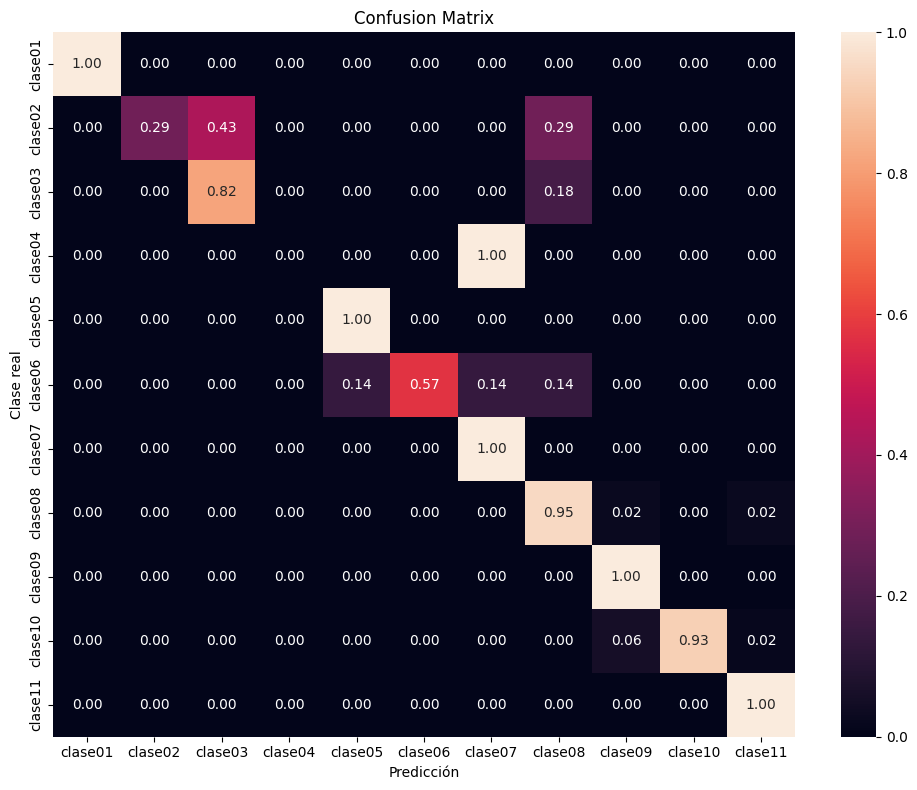

In [11]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [12]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS / f"model_{MODEL_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_relativa(ruta_modelo)}")

Modelo guardado en: output/models/model_resnet18_bs16_lr1e-3_flip05_base.pth
